In [ ]:
import sys, os
IN_COLAB = 'google.colab' in sys.modules
IN_KAGGLE = os.path.exists('/kaggle/input')
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DRIVE = '/content/drive/MyDrive/TerraSeg'
    OUT = f'{BASE_DRIVE}/phase9'
elif IN_KAGGLE:
    BASE_DRIVE = None
    OUT = '/kaggle/working/phase9'
else:
    BASE_DRIVE = None
    OUT = './phase9'
os.makedirs(f'{OUT}/runs', exist_ok=True)
print("Colab:", IN_COLAB, "| Kaggle:", IN_KAGGLE, "| outputs ->", OUT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Colab: True | Kaggle: True | outputs -> /content/drive/MyDrive/TerraSeg/phase9


In [ ]:
import sys
import subprocess

print("Python:", sys.version)
print("Executable:", sys.executable)

packages = [
    "numpy==2.2.3",
    "scipy==1.16.3",
    "pandas==2.2.3",
    "opencv-python-headless",
    "Pillow",
    "matplotlib",
    "tqdm",
]

subprocess.check_call([
    sys.executable, "-m", "pip", "install",
    "--no-cache-dir", *packages
])

print("Base dependencies installed.")

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Executable: /usr/bin/python3
Base dependencies installed.


In [ ]:
!pip -q install -U ultralytics segmentation_models_pytorch kaggle

In [ ]:
import glob, re, json, random, time, shutil
import numpy as np, pandas as pd, cv2
from PIL import Image
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F, torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import segmentation_models_pytorch as smp
from scipy.ndimage import binary_erosion, distance_transform_edt
from tqdm.auto import tqdm

IMG = 256                 # same size as notebook 08
SPLIT_SEED = 42           # same split as notebook 08
SEEDS = [42,123,777]              # FIRST pass; later [42, 123, 777]
EPOCHS, PATIENCE, LR, BATCH = 60, 10, 5e-4, 8
TARGET_RECALL = 0.85      # Bijie recall is high (~0.89), so we compare false alarms at 85% recall
FORCE = False
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
print("Device:", device)
if device.type == 'cpu':
    print("No GPU: Parts B, C, F and G still work; Part D (training) would be very slow. Use Kaggle or wait for Colab quota.")

Device: cuda


In [ ]:
if IN_KAGGLE:
    DATA_BASE = '/kaggle/input'
else:
    try:
        from google.colab import userdata
        os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
        os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')
        print("Kaggle credentials loaded from Colab secrets")
    except Exception:
        if not os.path.exists('/root/.kaggle/kaggle.json'):
            from google.colab import files
            print("Upload kaggle.json now:")
            up = files.upload()
            os.makedirs('/root/.kaggle', exist_ok=True)
            shutil.move(list(up.keys())[0], '/root/.kaggle/kaggle.json'); os.chmod('/root/.kaggle/kaggle.json', 0o600)
    import subprocess

zip_path = '/content/bijie-landslide-dataset.zip'
extract_path = '/content/bijie_data'
os.makedirs(extract_path, exist_ok=True)

result = subprocess.run(
    ['kaggle', 'datasets', 'download', '-d',
     'ksncik/bijie-landslide-dataset', '-p', '/content', '--force'],
    capture_output=True, text=True
)
print(result.stdout)
if result.returncode != 0:
    raise RuntimeError(result.stderr)

import zipfile

if not os.path.exists(zip_path):
    raise FileNotFoundError(f'Dataset ZIP not found: {zip_path}')

with zipfile.ZipFile(zip_path) as z:
    z.extractall(extract_path)

DATA_BASE = extract_path
print("Dataset extracted to:", DATA_BASE)
DATA_BASE = '/content/bijie_data'
print("data base:", DATA_BASE)

Dataset URL: https://www.kaggle.com/datasets/ksncik/bijie-landslide-dataset
License(s): unknown


Dataset extracted to: /content/bijie_data
data base: /content/bijie_data


In [ ]:
LS = None
for root, dirs, files in os.walk(DATA_BASE):
    if os.path.basename(root).lower() == 'landslide' and {'image', 'mask', 'dem'} <= {d.lower() for d in dirs}:
        LS = root
assert LS, "could not find a 'landslide' folder with image, mask and dem inside - look at the folder tree and tell me"
sub = {d.lower(): os.path.join(LS, d) for d in os.listdir(LS) if os.path.isdir(os.path.join(LS, d))}
IMG_DIR, MASK_DIR, DEM_DIR = sub['image'], sub['mask'], sub['dem']
print("landslide folder:", LS)

def pngs(d): return sorted(f for f in os.listdir(d) if f.lower().endswith('.png'))
img_names, mask_names, dem_names = pngs(IMG_DIR), pngs(MASK_DIR), pngs(DEM_DIR)
print(f"images {len(img_names)} | masks {len(mask_names)} | dems {len(dem_names)}")
assert len(img_names) == len(mask_names) == len(dem_names), "counts differ"
stem = lambda s: os.path.splitext(s)[0]
mm = sum(stem(a) != stem(b) for a, b in zip(img_names, mask_names))
md_ = sum(stem(a) != stem(b) for a, b in zip(img_names, dem_names))
print(f"name mismatches after sorting: image-vs-mask {mm} | image-vs-dem {md_}")
print("first names:", img_names[:2], mask_names[:2], dem_names[:2])
assert mm == 0 and md_ == 0, "image / mask / dem names do not line up - stop and send me this output"

for n in dem_names[:3]:
    d = cv2.imread(os.path.join(DEM_DIR, n), cv2.IMREAD_UNCHANGED)
    im = Image.open(os.path.join(IMG_DIR, n)).size
    extra = ""
    if d.ndim == 3:
        extra = f" | channels identical: {bool(np.all(d[..., 0] == d[..., 1]) and np.all(d[..., 0] == d[..., -1]))}"
    print(f"{n}: dem shape {d.shape} dtype {d.dtype} min {d.min()} max {d.max()} | image size (w,h) {im}{extra}")

landslide folder: /content/bijie_data/Bijie-landslide-dataset/landslide
images 770 | masks 770 | dems 770
name mismatches after sorting: image-vs-mask 0 | image-vs-dem 0
first names: ['df002.png', 'df003.png'] ['df002.png', 'df003.png'] ['df002.png', 'df003.png']
df002.png: dem shape (71, 91) dtype uint8 min 0 max 255 | image size (w,h) (121, 94)
df003.png: dem shape (65, 74) dtype uint8 min 0 max 255 | image size (w,h) (293, 258)
df004.png: dem shape (61, 61) dtype uint8 min 0 max 255 | image size (w,h) (61, 61)


### B3. Split (identical to notebook 08)

In [ ]:
n = len(img_names)
perm = np.random.RandomState(SPLIT_SEED).permutation(n)
n_tr, n_va = int(0.70 * n), int(0.15 * n)
SPLITS = {'train': np.sort(perm[:n_tr]), 'val': np.sort(perm[n_tr:n_tr + n_va]), 'test': np.sort(perm[n_tr + n_va:])}
print({k: len(v) for k, v in SPLITS.items()})

{'train': 539, 'val': 115, 'test': 116}


**Expected output:** `{'train': 539, 'val': 115, 'test': 116}` (the same sizes as in notebook 08; the test images are the same ones).

In [ ]:
def read_dem(path):
    d = cv2.imread(path, cv2.IMREAD_UNCHANGED)
    if d.ndim == 3:
        d = d[..., 0]
    return d.astype(np.float32)

def relief_of(dem):
    gy, gx = np.gradient(dem)
    return np.hypot(gx, gy)

N = n
X = np.zeros((N, 5, IMG, IMG), np.float32)       # R, G, B, DEM, relief
Y = np.zeros((N, 1, IMG, IMG), np.float32)
IMG_U8 = np.zeros((N, IMG, IMG, 3), np.uint8)    # kept for the YOLO part
for i in tqdm(range(N)):
    im = Image.open(os.path.join(IMG_DIR, img_names[i])).convert('RGB').resize((IMG, IMG), Image.BILINEAR)
    mk = Image.open(os.path.join(MASK_DIR, mask_names[i])).convert('L').resize((IMG, IMG), Image.NEAREST)
    dem = cv2.resize(read_dem(os.path.join(DEM_DIR, dem_names[i])), (IMG, IMG), interpolation=cv2.INTER_LINEAR)
    arr = np.array(im)
    IMG_U8[i] = arr
    X[i, :3] = arr.transpose(2, 0, 1).astype(np.float32) / 255.0
    X[i, 3] = dem
    X[i, 4] = relief_of(dem)
    Y[i, 0] = (np.array(mk) > 127)

tr = SPLITS['train']
print("raw ranges on training images (min / mean / max):")
for c, nm in enumerate(['R', 'G', 'B', 'DEM', 'relief']):
    print(f"  {nm:7s} {X[tr, c].min():10.3f} {X[tr, c].mean():10.3f} {X[tr, c].max():10.3f}")
print(f"landslide share of pixels: {Y.mean()*100:.1f}%")

  0%|          | 0/770 [00:00<?, ?it/s]

raw ranges on training images (min / mean / max):
  R            0.004      0.301      1.000
  G            0.004      0.368      1.000
  B            0.004      0.309      1.000
  DEM          0.000    116.935    255.000
  relief       0.000      0.989     24.853
landslide share of pixels: 10.1%


In [ ]:
if globals().get('NORMALISED', False):
    raise RuntimeError("Already normalised. Restart the session and run from the top.")
MEAN5 = X[tr].mean(axis=(0, 2, 3)).astype(np.float32)
STD5 = (X[tr].std(axis=(0, 2, 3)) + 1e-6).astype(np.float32)
json.dump({'mean': MEAN5.tolist(), 'std': STD5.tolist()}, open(f'{OUT}/norm_stats.json', 'w'))
RAW_X = X[SPLITS['test']].copy()                  # raw copy of test images for the pictures
X -= MEAN5.reshape(1, 5, 1, 1); X /= STD5.reshape(1, 5, 1, 1)
NORMALISED = True
print("normalised. train means ~", np.round(X[tr].mean(axis=(0, 2, 3)), 3), "| stds ~", np.round(X[tr].std(axis=(0, 2, 3)), 3))

normalised. train means ~ [-0. -0.  0. -0.  0.] | stds ~ [1. 1. 1. 1. 1.]


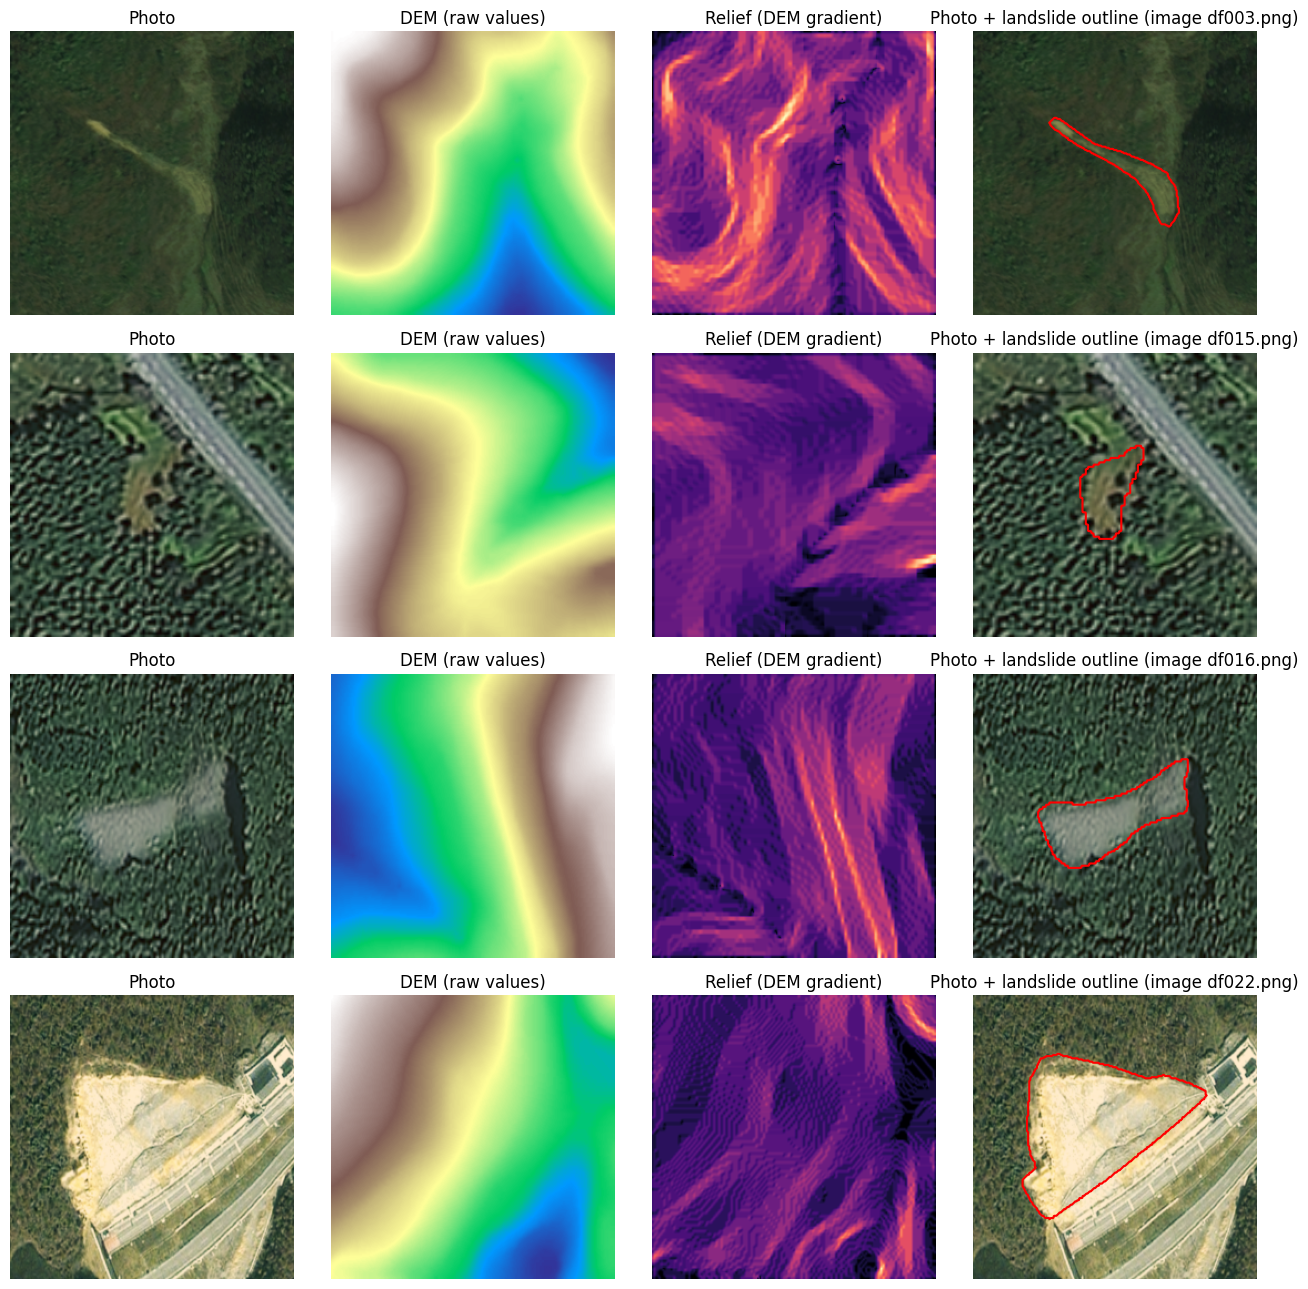

In [ ]:
test_idx = SPLITS['test']
fig, ax = plt.subplots(4, 4, figsize=(13, 13))
for r, k in enumerate(range(4)):
    raw = RAW_X[k]
    ax[r, 0].imshow(raw[:3].transpose(1, 2, 0)); ax[r, 0].set_title("Photo")
    ax[r, 1].imshow(raw[3], cmap='terrain'); ax[r, 1].set_title("DEM (raw values)")
    ax[r, 2].imshow(raw[4], cmap='magma'); ax[r, 2].set_title("Relief (DEM gradient)")
    ax[r, 3].imshow(raw[:3].transpose(1, 2, 0)); ax[r, 3].contour(Y[test_idx[k], 0], [0.5], colors='red', linewidths=1.5)
    ax[r, 3].set_title(f"Photo + landslide outline (image {img_names[test_idx[k]]})")
    for a in ax[r]: a.axis('off')
plt.tight_layout(); plt.savefig(f'{OUT}/bijie_alignment_check.png', dpi=130); plt.show()

In [ ]:
VARIANTS = {'RGB': [0, 1, 2], 'RGB+DEM': [0, 1, 2, 3], 'RGB+relief': [0, 1, 2, 4], 'RGB+DEM+relief': [0, 1, 2, 3, 4]}

class BijieDS(Dataset):
    def __init__(self, split, chans, aug=False):
        self.idx, self.chans, self.aug = SPLITS[split], list(chans), aug
    def __len__(self): return len(self.idx)
    def __getitem__(self, i):
        j = self.idx[i]
        x = torch.from_numpy(X[j][self.chans]); y = torch.from_numpy(Y[j].copy())
        if self.aug:
            if random.random() > 0.5: x, y = x.flip(-1), y.flip(-1)
            if random.random() > 0.5: x, y = x.flip(-2), y.flip(-2)
        return x, y

def dl(split, chans, aug=False, shuffle=False, bs=BATCH, seed=0):
    g = torch.Generator().manual_seed(seed)
    return DataLoader(BijieDS(split, chans, aug), batch_size=bs, shuffle=shuffle, generator=g if shuffle else None,
                      num_workers=2, pin_memory=True)

class BCEDiceLoss(nn.Module):
    def forward(self, logits, t):
        p, tf = torch.sigmoid(logits).view(-1), t.view(-1)
        return F.binary_cross_entropy_with_logits(logits, t) + 1 - (2 * (p * tf).sum() + 1e-6) / (p.sum() + tf.sum() + 1e-6)

@torch.no_grad()
def collect_probs(model, ldr):
    model.eval(); P, T = [], []
    for x, y in ldr:
        P.append(torch.sigmoid(model(x.to(device)))[:, 0].cpu().numpy().astype(np.float16)); T.append(y[:, 0].numpy().astype(np.uint8))
    return np.concatenate(P), np.concatenate(T)

def counts_metrics(P, T, thr):
    p, t = P.astype(np.float32) > thr, T == 1
    tp, fp, fn, tn = float((p & t).sum()), float((p & ~t).sum()), float((~p & t).sum()), float((~p & ~t).sum()); e = 1e-9
    pr, rc = tp / (tp + fp + e), tp / (tp + fn + e)
    return {'IoU': tp / (tp + fp + fn + e), 'F1': 2 * pr * rc / (pr + rc + e), 'Precision': pr, 'Recall': rc, 'tp': tp, 'fp': fp, 'fn': fn, 'tn': tn}

def boundary(m): return m & ~binary_erosion(m, border_value=0)
def boundary_f1(pred, gt, tol=2):
    bp, bg = boundary(pred), boundary(gt)
    if bg.sum() == 0 and bp.sum() == 0: return None
    if bg.sum() == 0 or bp.sum() == 0: return 0.0
    dg, dp = distance_transform_edt(~bg), distance_transform_edt(~bp)
    p, r = (dg[bp] <= tol).mean(), (dp[bg] <= tol).mean()
    return 0.0 if p + r == 0 else float(2 * p * r / (p + r))
def mean_boundary_f1(P, T, thr):
    v = [boundary_f1(P[i].astype(np.float32) > thr, T[i] == 1) for i in range(len(P)) if T[i].any()]
    v = [x for x in v if x is not None]
    return float(np.mean(v)) if v else 0.0

def rpath(name, seed): return f"{OUT}/runs/{name.replace('+', '_')}_s{seed}.json"
def cpath(name, seed): return f"{OUT}/runs/{name.replace('+', '_')}_s{seed}.pth"
THRS = np.round(np.arange(0.10, 0.91, 0.05), 2)

def run_variant(name, seed):
    if os.path.exists(rpath(name, seed)) and not FORCE:
        print(f"skip {name} seed {seed} (done)"); return json.load(open(rpath(name, seed)))
    chans = VARIANTS[name]
    print("\n" + "=" * 66 + f"\n{name} | seed {seed} | channels {chans}\n" + "=" * 66)
    set_seed(seed)
    tr_l, va_l, te_l = dl('train', chans, True, True, BATCH, seed), dl('val', chans, False, False, 16), dl('test', chans, False, False, 16)
    model = smp.Unet('resnet34', encoder_weights='imagenet', in_channels=len(chans), classes=1).to(device)
    crit, opt = BCEDiceLoss(), optim.Adam(model.parameters(), lr=LR)
    best, bad, ran, t0 = -1.0, 0, 0, time.time()
    for ep in range(EPOCHS):
        model.train(); run = 0.0
        for x, y in tr_l:
            x, y = x.to(device), y.to(device)
            opt.zero_grad(); loss = crit(model(x), y); loss.backward(); opt.step(); run += loss.item()
        Pv, Tv = collect_probs(model, va_l); v = counts_metrics(Pv, Tv, 0.5); ran = ep + 1
        print(f"[{name}/{seed}] ep {ran:02d} train {run/len(tr_l):.4f} | val IoU {v['IoU']:.4f} ({time.time()-t0:.0f}s)")
        if v['IoU'] > best: best, bad = v['IoU'], 0; torch.save(model.state_dict(), cpath(name, seed))
        else:
            bad += 1
            if bad >= PATIENCE: print("early stopping"); break
    model.load_state_dict(torch.load(cpath(name, seed), map_location=device))
    Pv, Tv = collect_probs(model, va_l); Pt, Tt = collect_probs(model, te_l)
    thr = float(THRS[int(np.argmax([counts_metrics(Pv, Tv, t)['IoU'] for t in THRS]))])
    test = counts_metrics(Pt, Tt, thr); test['Boundary F1'] = mean_boundary_f1(Pt, Tt, thr)
    res = {'name': name, 'seed': seed, 'channels': chans, 'epochs_run': ran, 'thr': thr, 'val_IoU': best, 'test': test}
    json.dump(res, open(rpath(name, seed), 'w'))
    print(f"TEST (thr {thr:.2f}) -> IoU {test['IoU']:.4f} | F1 {test['F1']:.4f} | P {test['Precision']:.4f} | R {test['Recall']:.4f} | boundary F1 {test['Boundary F1']:.4f}")
    del model, opt; torch.cuda.empty_cache()
    return res
print("ready")

ready


In [ ]:
for seed in SEEDS:
    for name in VARIANTS:
        run_variant(name, seed)
print("\nAll requested runs finished.")

skip RGB seed 42 (done)
skip RGB+DEM seed 42 (done)
skip RGB+relief seed 42 (done)
skip RGB+DEM+relief seed 42 (done)

RGB | seed 123 | channels [0, 1, 2]
[RGB/123] ep 01 train 0.7268 | val IoU 0.4675 (12s)
[RGB/123] ep 02 train 0.4299 | val IoU 0.5717 (23s)
[RGB/123] ep 03 train 0.3657 | val IoU 0.6111 (35s)
[RGB/123] ep 04 train 0.3526 | val IoU 0.6770 (48s)
[RGB/123] ep 05 train 0.3142 | val IoU 0.6877 (61s)
[RGB/123] ep 06 train 0.2865 | val IoU 0.6905 (74s)
[RGB/123] ep 07 train 0.2786 | val IoU 0.6877 (87s)
[RGB/123] ep 08 train 0.2777 | val IoU 0.7029 (98s)
[RGB/123] ep 09 train 0.2447 | val IoU 0.7315 (111s)
[RGB/123] ep 10 train 0.2659 | val IoU 0.6999 (124s)
[RGB/123] ep 11 train 0.2474 | val IoU 0.6868 (136s)
[RGB/123] ep 12 train 0.2276 | val IoU 0.7606 (149s)
[RGB/123] ep 13 train 0.2310 | val IoU 0.7255 (161s)
[RGB/123] ep 14 train 0.2169 | val IoU 0.7124 (173s)
[RGB/123] ep 15 train 0.2258 | val IoU 0.7401 (185s)
[RGB/123] ep 16 train 0.2177 | val IoU 0.7283 (197s)
[RGB/

In [ ]:
def load_runs():
    rows = []
    for f in sorted(glob.glob(f'{OUT}/runs/*.json')):
        r = json.load(open(f)); row = {'variant': r['name'], 'seed': r['seed'], 'val_IoU': r['val_IoU'], 'thr': r['thr']}
        row.update({f'test_{k}': v for k, v in r['test'].items()}); rows.append(row)
    return pd.DataFrame(rows)

df = load_runs()
g = df.groupby('variant')
tab = pd.DataFrame({'runs': g.size(), 'IoU': g['test_IoU'].mean(), 'IoU std': g['test_IoU'].std(), 'F1': g['test_F1'].mean(),
                    'Precision': g['test_Precision'].mean(), 'Recall': g['test_Recall'].mean(),
                    'Boundary F1': g['test_Boundary F1'].mean(), 'FP pixels': g['test_fp'].mean()}).reindex([v for v in VARIANTS if v in g.groups])
tab['IoU gain vs RGB'] = tab['IoU'] - tab.loc['RGB', 'IoU']
tab['gain / std'] = tab['IoU gain vs RGB'] / np.sqrt((tab['IoU std'] ** 2 + tab.loc['RGB', 'IoU std'] ** 2) / 2)
tab['FP change vs RGB %'] = (tab['FP pixels'] - tab.loc['RGB', 'FP pixels']) / tab.loc['RGB', 'FP pixels'] * 100
display(tab.round(4)); tab.round(4).to_csv(f'{OUT}/phase9_bijie_terrain.csv')

,runs,IoU,IoU std,F1,Precision,Recall,Boundary F1,FP pixels,IoU gain vs RGB,gain / std,FP change vs RGB %
variant,,,,,,,,,,,
RGB,3,0.7889,0.0178,0.8819,0.8696,0.8948,0.4199,108543.3333,0.0000,0.0000,0.0000
RGB+DEM,3,0.7794,0.0265,0.8759,0.8679,0.8840,0.4183,108799.6667,-0.0095,-0.4188,0.2362
RGB+relief,3,0.7903,0.0060,0.8828,0.8672,0.8991,0.4191,111453.0000,0.0014,0.1041,2.6806
RGB+DEM+relief,3,0.7772,0.0258,0.8744,0.8596,0.8899,0.3985,117869.3333,-0.0117,-0.5290,8.5920


,threshold,test recall,test precision,FP pixels,FP reduction vs RGB %
variant,,,,,
RGB,0.85,0.89,0.89,90867,0.00
RGB+DEM,0.80,0.88,0.90,75589,16.81
RGB+relief,0.60,0.87,0.90,78848,13.23
RGB+DEM+relief,0.85,0.88,0.90,81066,10.79


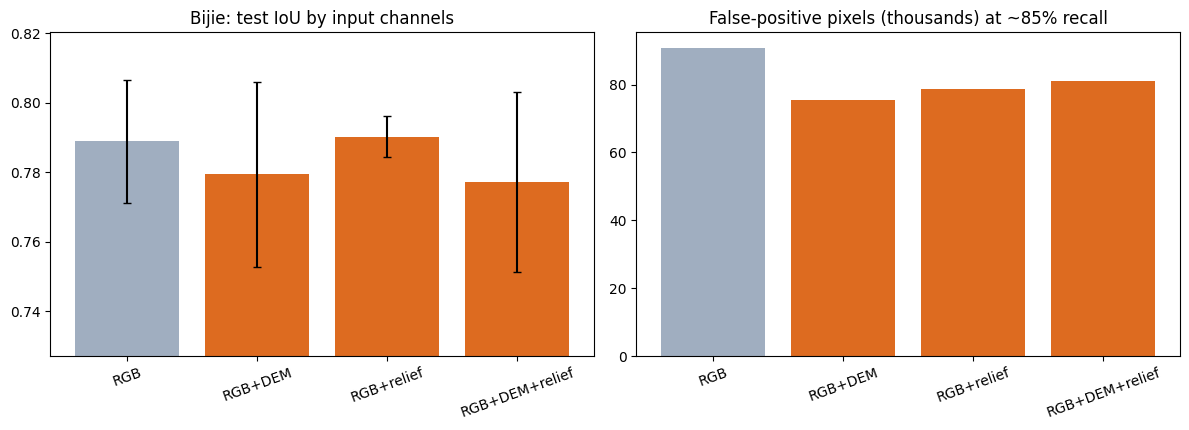

In [ ]:
def fp_at_recall(name, seed=42, target=TARGET_RECALL):
    chans = VARIANTS[name]
    model = smp.Unet('resnet34', encoder_weights=None, in_channels=len(chans), classes=1).to(device)
    model.load_state_dict(torch.load(cpath(name, seed), map_location=device)); model.eval()
    Pv, Tv = collect_probs(model, dl('val', chans, False, False, 16)); Pt, Tt = collect_probs(model, dl('test', chans, False, False, 16))
    chosen = 0.05
    for thr in np.arange(0.95, 0.049, -0.05):
        if counts_metrics(Pv, Tv, thr)['Recall'] >= target: chosen = float(thr); break
    m = counts_metrics(Pt, Tt, chosen); del model; torch.cuda.empty_cache()
    return {'variant': name, 'threshold': round(chosen, 2), 'test recall': round(m['Recall'], 3), 'test precision': round(m['Precision'], 3), 'FP pixels': int(m['fp'])}

fp_rows = [fp_at_recall(n) for n in VARIANTS if os.path.exists(cpath(n, 42))]
fp_tab = pd.DataFrame(fp_rows).set_index('variant')
fp_tab['FP reduction vs RGB %'] = (fp_tab.loc['RGB', 'FP pixels'] - fp_tab['FP pixels']) / fp_tab.loc['RGB', 'FP pixels'] * 100
display(fp_tab.round(2)); fp_tab.round(2).to_csv(f'{OUT}/phase9_false_alarms_at_recall.csv')

fig, ax = plt.subplots(1, 2, figsize=(12, 4.4)); names = list(tab.index); xs = np.arange(len(names))
err = tab['IoU std'].fillna(0).values if tab['runs'].max() > 1 else None
ax[0].bar(xs, tab['IoU'].values, yerr=err, capsize=3, color=['#a0aec0'] + ['#dd6b20'] * (len(names) - 1)); ax[0].set_xticks(xs); ax[0].set_xticklabels(names, rotation=20)
ax[0].set_title("Bijie: test IoU by input channels"); ax[0].set_ylim(max(0, tab['IoU'].min() - 0.05), min(1, tab['IoU'].max() + 0.03))
ax[1].bar(range(len(fp_tab)), fp_tab['FP pixels'].values / 1000, color=['#a0aec0'] + ['#dd6b20'] * (len(fp_tab) - 1))
ax[1].set_xticks(range(len(fp_tab))); ax[1].set_xticklabels(fp_tab.index, rotation=20); ax[1].set_title(f"False-positive pixels (thousands) at ~{int(TARGET_RECALL*100)}% recall")
plt.tight_layout(); plt.savefig(f'{OUT}/phase9_bijie_terrain.png', dpi=150); plt.show()

In [ ]:
YOLO_W = f'{BASE_DRIVE}/phase8/runs/yolo_s42/weights/best.pt' if BASE_DRIVE else None
HAVE_YOLO = bool(YOLO_W) and os.path.exists(YOLO_W)
print("YOLO weights found:", HAVE_YOLO)

def render_maps(cache, thr, size=IMG):
    maps = []
    for item in cache:
        m = np.zeros((size, size), np.uint8)
        for poly, sc in zip(item['polys'], item['scores']):
            if sc >= thr: cv2.fillPoly(m, [np.round(poly).astype(np.int32)], 1)
        maps.append(m.astype(bool))
    return maps

def top1(cache):
    out = []
    for item in cache:
        if item['scores']:
            k = int(np.argmax(item['scores']))
            out.append({'polys': [item['polys'][k]], 'scores': [item['scores'][k]], 'boxes': [item['boxes'][k]]})
        else:
            out.append({'polys': [], 'scores': [], 'boxes': []})
    return out

def pixel_scores(preds, gts):
    tp = fp = fn = 0.0; bfs = []
    for p, g in zip(preds, gts):
        tp += (p & g).sum(); fp += (p & ~g).sum(); fn += (~p & g).sum()
        if g.any():
            b = boundary_f1(p, g)
            if b is not None: bfs.append(b)
    e = 1e-9; P, R = tp / (tp + fp + e), tp / (tp + fn + e)
    return {'IoU': round(tp / (tp + fp + fn + e), 4), 'F1': round(2 * P * R / (P + R + e), 4), 'Precision': round(P, 4),
            'Recall': round(R, 4), 'Boundary F1': round(float(np.mean(bfs)) if bfs else 0.0, 4)}

if HAVE_YOLO:
    from ultralytics import YOLO
    yolo = YOLO(YOLO_W)
    def predict_split(split):
        d = f'/content/yolo_eval/{split}'; shutil.rmtree(d, ignore_errors=True); os.makedirs(d)
        for j in SPLITS[split]: Image.fromarray(IMG_U8[j]).save(f'{d}/b{int(j):04d}.png')
        files = sorted(glob.glob(f'{d}/*.png')); out = []
        for r in yolo.predict(source=files, imgsz=IMG, conf=0.05, iou=0.7, max_det=50, stream=True, verbose=False, batch=16, device=device.type if device.type == 'cpu' else 0):
            polys, scores, boxes = [], [], []
            if r.masks is not None and len(r.masks.xy) > 0:
                for poly, sc, bx in zip(r.masks.xy, r.boxes.conf.cpu().numpy(), r.boxes.xyxy.cpu().numpy()):
                    if len(poly) >= 3: polys.append(poly); scores.append(float(sc)); boxes.append(bx)
            out.append({'polys': polys, 'scores': scores, 'boxes': boxes})
        return out
    cache_v, cache_t = predict_split('val'), predict_split('test')
    gts_v = [Y[j, 0] > 0.5 for j in SPLITS['val']]; gts_t = [Y[j, 0] > 0.5 for j in SPLITS['test']]
    cs = np.round(np.arange(0.05, 0.80, 0.05), 2)
    best_c = float(cs[int(np.argmax([pixel_scores(render_maps(cache_v, c), gts_v)['IoU'] for c in cs]))])
    rows = [{'YOLO variant': f'all objects, conf >= {best_c} (as in notebook 08)', **pixel_scores(render_maps(cache_t, best_c), gts_t)},
            {'YOLO variant': 'best object per image only (uses the one-landslide-per-image rule)', **pixel_scores(render_maps(top1(cache_t), 0.0), gts_t)}]
    yolo_tab = pd.DataFrame(rows).set_index('YOLO variant'); display(yolo_tab); yolo_tab.to_csv(f'{OUT}/phase9_yolo_top1.csv')
    print("objects per test image with the plain rule: mean", round(float(np.mean([sum(s >= best_c for s in c['scores']) for c in cache_t])), 2))

YOLO weights found: False
